In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path.cwd().parent  
RAW = BASE / "Data" / "Raw" / "Transactions sale for real estate Excel.xlsx"
OUT = BASE / "Data" / "Processed"
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_excel(RAW)
print(df.shape)

Project folder: /Users/amal/Desktop/real-estate-transactions-analysis
Raw file exists: True
(201556, 10)


In [2]:

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nBasic statistics:")
display(df.describe())



Data types:
المنطقة                     str
المدينة                     str
المدينة / الحي              str
الرقم المرجعي للصفقة      int64
تاريخ الصفقة ميلادي         str
تاريخ الصفقة هجري           str
تصنيف العقار                str
عدد العقارات              int64
السعر                   float64
المساحة                 float64
dtype: object

Missing values:
المنطقة                 0
المدينة                 0
المدينة / الحي          0
الرقم المرجعي للصفقة    0
تاريخ الصفقة ميلادي     0
تاريخ الصفقة هجري       0
تصنيف العقار            0
عدد العقارات            0
السعر                   0
المساحة                 0
dtype: int64

Duplicate rows: 0

Basic statistics:


,الرقم المرجعي للصفقة,عدد العقارات,السعر,المساحة
count,2.015560e+05,201556.000000,2.015560e+05,2.015560e+05
mean,3.022651e+07,1.025720,1.086624e+06,4.931465e+03
std,2.162743e+06,0.956364,1.017678e+07,7.617607e+04
min,2.486826e+07,1.000000,5.000000e+03,3.300000e-01
25%,2.823217e+07,1.000000,1.656150e+05,3.000000e+02
50%,3.005842e+07,1.000000,4.458525e+05,4.656500e+02
75%,3.212886e+07,1.000000,8.450000e+05,6.720000e+02
max,3.423832e+07,311.000000,2.437000e+09,1.024956e+07


In [3]:

date_col = "تاريخ الصفقة ميلادي"

print(df[date_col].map(type).value_counts())

print("\nSample dates:")
print(df[date_col].head(10).tolist())

print("\nLast dates:")
print(df[date_col].tail(10).tolist())


تاريخ الصفقة ميلادي
<class 'str'>    201556
Name: count, dtype: int64

Sample dates:
['2025/01/01', '2025/01/01', '2025/01/01', '2025/01/01', '2025/01/01', '2025/01/01', '2025/01/01', '2025/01/01', '2025/01/01', '2025/01/01']

Last dates:
['2025/12/31', '2025/12/31', '2025/12/31', '2025/12/31', '2025/12/31', '2025/12/31', '2025/12/31', '2025/12/31', '2025/12/31', '2025/12/31']


In [4]:

df["تاريخ الصفقة ميلادي"] = pd.to_datetime(
    df["تاريخ الصفقة ميلادي"],
    format="%Y/%m/%d",
    errors="coerce"
)

print("Data type:", df["تاريخ الصفقة ميلادي"].dtype)
print("Missing dates:", df["تاريخ الصفقة ميلادي"].isna().sum())
print("Earliest date:", df["تاريخ الصفقة ميلادي"].min())
print("Latest date:", df["تاريخ الصفقة ميلادي"].max())


Data type: datetime64[us]
Missing dates: 0
Earliest date: 2025-01-01 00:00:00
Latest date: 2025-12-31 00:00:00


In [21]:
missing = df.isnull().sum()
print(missing[missing > 0] if missing.any() else "None")
invalid = (df[["السعر", "المساحة"]] <= 0).any(axis=1)
print("\nRows with price <= 0 or area <= 0:", int(invalid.sum()))

None

Rows with price <= 0 or area <= 0: 0


In [7]:
print("Highest prices:")
display(df.nlargest(10, "السعر")[
    ["المنطقة", "المدينة", "المدينة / الحي", "تصنيف العقار",
     "عدد العقارات", "السعر", "المساحة", "تاريخ الصفقة ميلادي"]
])

print("\nLargest areas:")
display(df.nlargest(10, "المساحة")[
    ["المنطقة", "المدينة", "المدينة / الحي", "تصنيف العقار",
     "عدد العقارات", "السعر", "المساحة", "تاريخ الصفقة ميلادي"]
])

print("\nHighest property counts:")
display(df.nlargest(10, "عدد العقارات")[
    ["المنطقة", "المدينة", "المدينة / الحي", "تصنيف العقار",
     "عدد العقارات", "السعر", "المساحة"]
])

Highest prices:


,المنطقة,المدينة,المدينة / الحي,تصنيف العقار,عدد العقارات,السعر,المساحة,تاريخ الصفقة ميلادي
199147,منطقة الرياض,الرياض,الرياض/الياسمين,تجاري,1,2.437000e+09,587228.97,2025-12-28
59418,منطقة الرياض,الدرعيه,الدرعيه/أخرى,سكني,1,1.239867e+09,137763.03,2025-03-20
98876,منطقة الرياض,الرياض,الرياض/قرطبة,تجاري,1,1.142521e+09,228504.17,2025-06-04
150211,منطقة مكة المكرمه,جده,جده/ الشاطئ,تجاري,1,9.855294e+08,135717.35,2025-09-16
171412,منطقة الرياض,الرياض,الرياض/الملز,سكني,1,8.500000e+08,3495.92,2025-10-28
43778,منطقة الرياض,الرياض,الرياض/النرجس,سكني,1,7.500000e+08,46055.01,2025-02-27
53300,منطقة الرياض,الرياض,الرياض/ السحاب,تجاري,3,6.787394e+08,646418.50,2025-03-12
99488,منطقة الرياض,الدرعيه,الدرعيه/ العاصمه,تجاري,1,6.500000e+08,10325.82,2025-06-06
31234,منطقة الرياض,الرياض,الرياض/العماجية,تجاري,1,6.443326e+08,2369438.41,2025-02-11
38609,منطقة مكة المكرمه,جده,جده/ خليج سلمان,سكني,1,6.000000e+08,3620200.00,2025-02-20



Largest areas:


,المنطقة,المدينة,المدينة / الحي,تصنيف العقار,عدد العقارات,السعر,المساحة,تاريخ الصفقة ميلادي
187335,منطقة الرياض,الدلم,الدلم/ طريق العيون,زراعي,1,1.024956e+08,10249565.00,2025-12-02
180318,منطقة الشرقية,قرية العليا,قرية العليا/أخرى,زراعي,1,1.850000e+07,8000000.00,2025-11-17
114471,منطقة القصيم,الشماسيه,الشماسيه/أخرى,زراعي,1,3.179348e+06,5381766.03,2025-07-10
196982,منطقة الرياض,ضرماء,ضرماء/أخرى,زراعي,1,1.153102e+08,5241374.00,2025-12-23
164889,منطقة الرياض,الغاط,الغاط/ حمادة الغاط,زراعي,1,2.500000e+07,4485072.50,2025-10-16
146810,منطقة القصيم,عيون الجوى,عيون الجوى/ شمال شرق غاف الجواء,زراعي,1,5.000000e+06,4000000.00,2025-09-09
158825,منطقة القصيم,بريده,بريده/أخرى,زراعي,1,3.981134e+07,4000000.00,2025-10-05
129506,منطقة الرياض,الدلم,الدلم/ خارج حدود الأحياء,سكني,1,1.656540e+08,3637254.13,2025-08-05
38609,منطقة مكة المكرمه,جده,جده/ خليج سلمان,سكني,1,6.000000e+08,3620200.00,2025-02-20
86034,منطقة القصيم,البكيريه,البكيريه/ الربوة,زراعي,1,2.128789e+07,3547982.00,2025-05-12



Highest property counts:


,المنطقة,المدينة,المدينة / الحي,تصنيف العقار,عدد العقارات,السعر,المساحة
9316,منطقة الرياض,حريملاء,حريملاء/أخرى,زراعي,311,3.547989e+08,3460629.33
9315,منطقة الرياض,حريملاء,حريملاء/أخرى,زراعي,210,2.551736e+08,2414542.09
59908,منطقة الرياض,حريملاء,حريملاء/أخرى,زراعي,76,1.254502e+08,1511225.76
59909,منطقة الرياض,حريملاء,حريملاء/أخرى,زراعي,73,4.276628e+08,1485036.27
197106,منطقة الشرقية,الخبر,الخبر/ اشبيليا,تجاري,27,1.200000e+07,3251.53
23835,منطقة الرياض,الرياض,الرياض/طيبة,سكني,26,6.561000e+07,24300.00
68456,منطقة مكة المكرمه,جده,جده/ المروة,تجاري,24,1.951276e+08,27875.37
7922,منطقة الرياض,الرياض,الرياض/نمار,سكني,22,1.975567e+07,19755.67
13261,منطقة الرياض,الرياض,الرياض/نمار,سكني,22,1.550000e+07,13199.74
110772,منطقة الشرقية,الخبر,الخبر/ الراكة الجنوبية,تجاري,22,7.283803e+07,23496.14


Categorical Data

In [8]:

print(df["المنطقة"].value_counts())

print("\nCities:")
print(df["المدينة"].value_counts().head(10))

print("\nProperty types:")
print(df["تصنيف العقار"].value_counts())


المنطقة
منطقة الرياض             52770
منطقة مكة المكرمه        50950
منطقة الشرقية            31156
منطقة القصيم             14332
منطقة المدينة المنوره    12336
منطقة حائل               10513
منطقة عسير                9317
منطقة جازان               5017
منطقة تبوك                4679
منطقة الجوف               3462
منطقة نجران               2975
منطقة الحدود الشمالية     2924
منطقة الباحة              1125
Name: count, dtype: int64

Cities:
المدينة
الرياض             34060
جده                31711
المدينة المنورة    10942
مكة المكرمة         9683
بريده               6684
الدمام              5961
حائل                5732
الخبر               5586
الطائف              5496
الهفوف              5128
Name: count, dtype: int64

Property types:
تصنيف العقار
سكني          182376
تجاري          12748
زراعي           6431
سكني تجاري         1
Name: count, dtype: int64


In [9]:
print("Top 10 neighborhoods:")
display(
    df["المدينة / الحي"]
    .value_counts()
    .head(10)
    .to_frame("عدد الصفقات")
)

Top 10 neighborhoods:


,عدد الصفقات
المدينة / الحي,
الرياض/الجنادرية,5301
الرياض/نمار,2769
الرياض/الرمال,2461
مكة المكرمة/ القناديل,1593
الرياض/النظيم,1545
الرياض/الخير,1431
جده/ مريخ,1383
الرياض/عريض,1340
الطائف/ الورود,1311


In [25]:
neighborhood_stats = (
    df.groupby("المدينة / الحي")
    .agg(
        عدد_الصفقات=("السعر", "count"),
        متوسط_السعر=("السعر", "mean"),
        وسيط_السعر=("السعر", "median"),
        متوسط_المساحة=("المساحة", "mean")
    )
    .reset_index()
)

neighborhood_stats = neighborhood_stats[
    neighborhood_stats["عدد_الصفقات"] >= 50 #الاحياء الاقل من 50 مستبعده 
]

display(
    neighborhood_stats
    .sort_values("وسيط_السعر", ascending=False)
    .head(10)
    .round(2)
)

,المدينة / الحي,عدد_الصفقات,متوسط_السعر,وسيط_السعر,متوسط_المساحة
1188,الدمام/ غرب الدمام,97,20200141.54,13750000.0,159438.57
4542,جده/ الوادي,57,5410835.80,5086000.0,4017.29
1052,الدرعيه/أخرى,149,13358854.39,5000000.0,10810.73
4448,جده/ الخالدية,51,4905752.18,4370600.0,771.09
4477,جده/ الشاطئ,162,15354776.15,4000000.0,1806.80
4604,جده/الفردوس,66,3806822.93,3969000.0,947.31
4511,جده/ المرجان,73,9477941.41,3950000.0,1412.92
4471,جده/ السروات,50,5048900.60,3920000.0,3335.93
1366,الرياض/العليا,203,6117212.10,3500000.0,556.63
4594,جده/البساتين,128,4604994.35,3285000.0,709.96


In [26]:
df["سعر المتر"] = df["السعر"] / df["المساحة"]

neighborhood_prices = (
    df.groupby("المدينة / الحي")
    .agg(
        عدد_الصفقات=("السعر", "count"),
        وسيط_سعر_المتر=("سعر المتر", "median")
    )
    .reset_index()
)

neighborhood_prices = neighborhood_prices[
    (neighborhood_prices["عدد_الصفقات"] >= 50)
    & (~neighborhood_prices["المدينة / الحي"].str.contains(
        "أخرى|خارج حدود الأحياء", na=False
    ))
]

display(
    neighborhood_prices
    .sort_values("وسيط_سعر_المتر", ascending=False)
    .head(10)
    .round(2)
)

,المدينة / الحي,عدد_الصفقات,وسيط_سعر_المتر
1356,الرياض/الصحافة,167,12035.11
1438,الرياض/حطين,137,11397.21
6586,مكة المكرمة/ المعابدة,291,10613.46
1398,الرياض/المغرزات,67,10122.87
1391,الرياض/المروج,64,9978.16
1366,الرياض/العليا,203,9876.54
1396,الرياض/المعذر,63,9750.00
1400,الرياض/الملقا,244,9692.45
1349,الرياض/السليمانية,116,9139.77
1365,الرياض/العقيق,62,9096.74


In [27]:
df["سعر المتر"] = df["السعر"] / df["المساحة"]

neighborhood_prices = (
    df.groupby("المدينة / الحي")
    .agg(
        عدد_الصفقات=("السعر", "count"),
        وسيط_سعر_المتر=("سعر المتر", "median")
    )
    .reset_index()
)

neighborhood_prices = neighborhood_prices[
    (neighborhood_prices["عدد_الصفقات"] >= 50)
    & (~neighborhood_prices["المدينة / الحي"].str.contains(
        "أخرى|خارج حدود الأحياء", na=False
    ))
]

display(
    neighborhood_prices
    .sort_values("وسيط_سعر_المتر", ascending=True)
    .head(10)
    .round(2)
)

,المدينة / الحي,عدد_الصفقات,وسيط_سعر_المتر
5855,طبرجل/ بسيطاء,62,0.18
3859,بريده/ شمال أبلق,64,10.00
5877,طريب/ خارج حدود الاحياء,145,13.33
870,الخرج/ الحنيه,158,14.16
5874,طريب/ الملك فهد,93,14.29
5796,ضرماء/ شمال الجلة,106,19.25
4029,بيش/ الخضراء1,443,22.22
6012,عفيف/ حى الريان,84,25.00
6013,عفيف/ حى الشلال,54,25.97
4873,حبونا/ المنتشر,170,27.21


In [13]:
monthly_sales = (
    df.groupby(df["تاريخ الصفقة ميلادي"].dt.month)
    .agg(
        عدد_الصفقات=("السعر", "count"),
        إجمالي_قيمة_الصفقات=("السعر", "sum"),
        متوسط_السعر=("السعر", "mean")
    )
    .reset_index()
    .rename(columns={"تاريخ الصفقة ميلادي": "الشهر"})
)

display(monthly_sales.round(2))

,الشهر,عدد_الصفقات,إجمالي_قيمة_الصفقات,متوسط_السعر
0,1,22319,2.518260e+10,1128303.39
1,2,22726,2.687078e+10,1182380.54
2,3,20683,2.658983e+10,1285588.63
3,4,14264,1.364957e+10,956924.73
4,5,17456,1.954141e+10,1119466.47
5,6,10798,1.216264e+10,1126378.62
6,7,19043,1.734678e+10,910927.03
7,8,14889,1.497892e+10,1006039.34
8,9,14888,1.384757e+10,930116.26
9,10,16255,1.748621e+10,1075743.16


In [30]:

df_work = df[df["تصنيف العقار"] != "سكني تجاري"].copy()


log_ppm = np.log10(df_work["سعر المتر"])
grp = log_ppm.groupby(df_work["تصنيف العقار"])
q1 = grp.transform(lambda s: s.quantile(0.25))
q3 = grp.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

mask = (log_ppm >= q1 - 1.5 * iqr) & (log_ppm <= q3 + 1.5 * iqr)
df_final = df_work[mask].copy()



df_final.to_csv(OUT / "real_estate_cleaned.csv", index=False, encoding="utf-8-sig")


In [34]:
total = df_work.groupby("تصنيف العقار").size()
after = df_final.groupby("تصنيف العقار").size()
after = after.reindex(total.index, fill_value=0)

removed = total - after

removal_summary = pd.DataFrame({
    "Before": total,
    "After": after,
    "Removed": removed,
    "Removal Rate (%)": (removed / total * 100).round(2)
})
print("قبل:", len(df_work), "| بعد:", len(df_final), "| المستبعد:", len(df_work) - len(df_final))

display(removal_summary)
print("\nMedian price per m²:")
print("Before:", df_work["سعر المتر"].median())
print("After:", df_final["سعر المتر"].median())

قبل: 201555 | بعد: 197897 | المستبعد: 3658


,Before,After,Removed,Removal Rate (%)
تصنيف العقار,,,,
تجاري,12748,12118,630,4.94
زراعي,6431,6413,18,0.28
سكني,182376,179366,3010,1.65



Median price per m²:
Before: 1045.9035474006116
After: 1088.888888888889


In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)

type_map = {"سكني": "Residential", "تجاري": "Commercial", "زراعي": "Agricultural"}

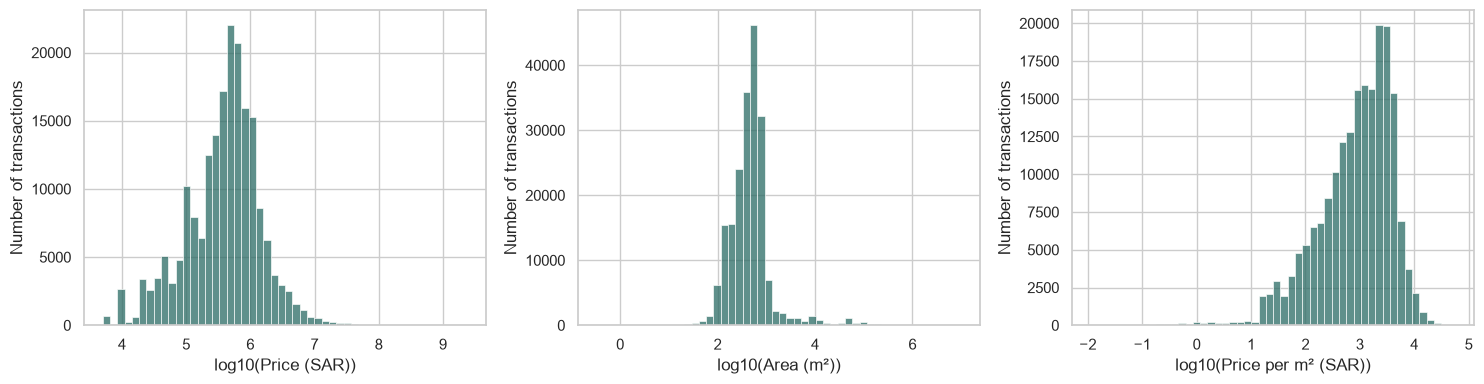

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
items = [("السعر", "Price (SAR)"), ("المساحة", "Area (m²)"), ("سعر المتر", "Price per m² (SAR)")]

for ax, (col, label) in zip(axes, items):
    sns.histplot(np.log10(df_final[col]), bins=50, ax=ax, color="#2a6b64")
    ax.set_xlabel(f"log10({label})")
    ax.set_ylabel("Number of transactions")

plt.tight_layout()
plt.savefig(FIG / "distributions.png", dpi=200)
plt.show()

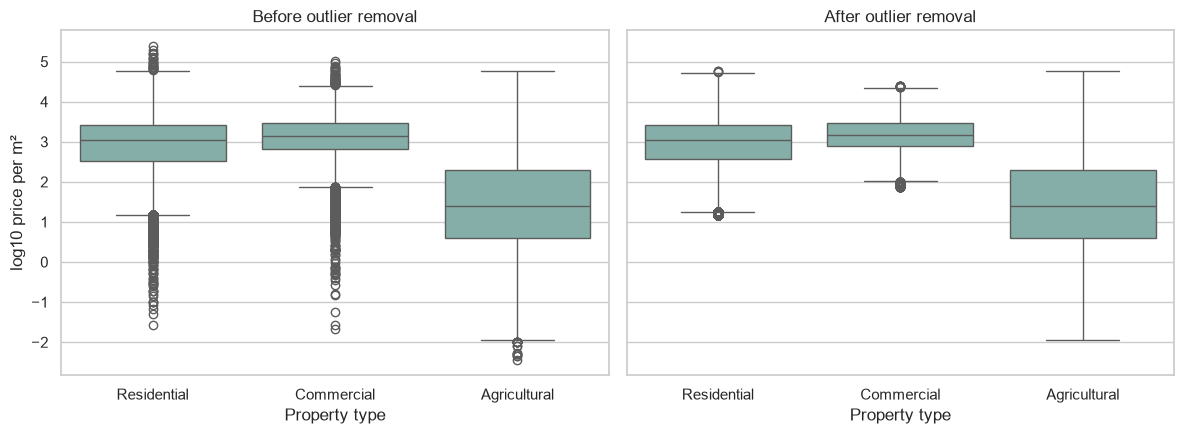

In [19]:
def prep(d):
    d = d.copy()
    d["Property type"] = d["تصنيف العقار"].map(type_map)
    d["log10 price per m²"] = np.log10(d["سعر المتر"])
    return d

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, d, title in zip(axes, [prep(df_work), prep(df_final)],
                        ["Before outlier removal", "After outlier removal"]):
    sns.boxplot(data=d, x="Property type", y="log10 price per m²", ax=ax, color="#7fb5ad")
    ax.set_title(title)

plt.tight_layout()
plt.savefig(FIG / "outliers_before_after.png", dpi=200)
plt.show()

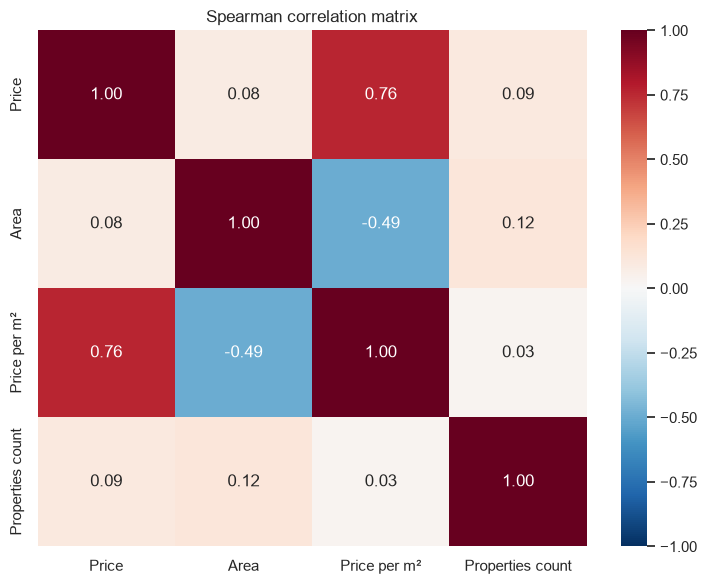

                  Price  Area  Price per m²  Properties count
Price              1.00  0.08          0.76              0.09
Area               0.08  1.00         -0.49              0.12
Price per m²       0.76 -0.49          1.00              0.03
Properties count   0.09  0.12          0.03              1.00


In [20]:
corr_df = df_final[["السعر", "المساحة", "سعر المتر", "عدد العقارات"]].rename(columns={
    "السعر": "Price", "المساحة": "Area",
    "سعر المتر": "Price per m²", "عدد العقارات": "Properties count"})

corr = corr_df.corr(method="spearman")

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Spearman correlation matrix")
plt.tight_layout()
plt.savefig(FIG / "correlation.png", dpi=200)
plt.show()
print(corr.round(2))